In [1]:
import os

data_path = "../data/raw"

print(os.listdir(data_path))

['test-20261007T203009Z-1-001', 'train-20261007T203015Z-1-001', 'valid-20261007T203007Z-1-001']


In [2]:
import os

train_path = "../data/raw/train-20261007T203015Z-1-001"

print(os.listdir(train_path))

['train']


In [3]:
import os

print(os.listdir("../data/raw/train-20261007T203015Z-1-001/train"))


['glioma', 'meningioma', 'no_tumor', 'pituitary', '_classes.csv']


In [4]:
import os

train_path = "../data/raw/train-20261007T203015Z-1-001/train"

for folder in os.listdir(train_path):

    folder_path = os.path.join(train_path, folder)

    if os.path.isdir(folder_path):

        count = len(os.listdir(folder_path))

        print(folder, ":", count)

glioma : 564
meningioma : 358
no_tumor : 335
pituitary : 438


Image Shape: (640, 640, 3)


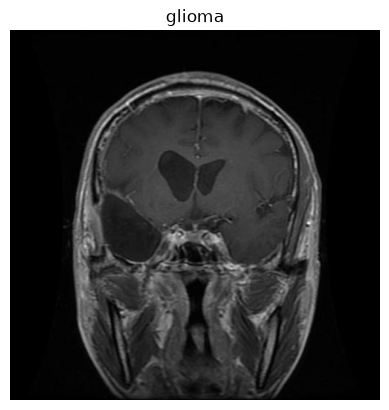

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

train_path = "../data/raw/train-20261007T203015Z-1-001/train"

class_name = "glioma"

image_name = os.listdir(
    os.path.join(train_path, class_name)
)[0]

image_path = os.path.join(
    train_path,
    class_name,
    image_name
)

img = cv2.imread(image_path)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(class_name)
plt.axis("off")

print("Image Shape:", img.shape)

In [3]:
import cv2
import os

train_path = "../data/raw/train-20261007T203015Z-1-001/train/glioma"

image_name = os.listdir(train_path)[0]

image_path = os.path.join(train_path, image_name)

img = cv2.imread(image_path)

print("Original Shape:", img.shape)

img = cv2.resize(img, (224,224))

print("After Resize:", img.shape)

Original Shape: (640, 640, 3)
After Resize: (224, 224, 3)


In [ ]:
import cv2
import os

train_path = "../data/raw/train-20261007T203015Z-1-001/train/glioma"

image_name = os.listdir(train_path)[0]

image_path = os.path.join(train_path, image_name)

img = cv2.imread(image_path)

img = cv2.resize(img, (224, 224))

print("Before Normalization")
print("Min Value:", img.min())
print("Max Value:", img.max())

img = img / 255.0

print("\nAfter Normalization")
print("Min Value:", img.min())
print("Max Value:", img.max())

Before Normalization
Min Value: 0
Max Value: 226

After Normalization
Min Value: 0.0
Max Value: 0.8862745098039215


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8,1.2]
)

print("Data Augmentation Ready")

Data Augmentation Ready


In [6]:
train_dir = "../data/raw/train-20261007T203015Z-1-001/train"
valid_dir = "../data/raw/valid-20261007T203007Z-1-001/valid"
test_dir = "../data/raw/test-20261007T203009Z-1-001/test"

print("Train Folder :", train_dir)
print("Validation Folder :", valid_dir)
print("Test Folder :", test_dir)


Train Folder : ../data/raw/train-20261007T203015Z-1-001/train
Validation Folder : ../data/raw/valid-20261007T203007Z-1-001/valid
Test Folder : ../data/raw/test-20261007T203009Z-1-001/test


In [7]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

validation_generator = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    valid_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

test_generator = ImageDataGenerator(
    rescale=1./255
).flow_from_directory(
    test_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([

    Conv2D(
        32,
        (3,3),
        activation="relu",
        input_shape=(224,224,3)
    ),

    MaxPooling2D((2,2)),

    Conv2D(
        64,
        (3,3),
        activation="relu"
    ),

    MaxPooling2D((2,2)),

    Conv2D(
        128,
        (3,3),
        activation="relu"
    ),

    MaxPooling2D((2,2)),

    BatchNormalization(),

    Flatten(),

    Dense(
        256,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        4,
        activation="softmax"
    )
])

model.summary()


c:\Users\Nithin\Brain-Tumor-Classification\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,246,212 (84.86 MB)

 Trainable params: 22,245,956 (84.86 MB)

 Non-trainable params: 256 (1.00 KB)

In [9]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully")

Model Compiled Successfully


In [10]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 50s 895ms/step - accuracy: 0.4490 - loss: 6.3039 - val_accuracy: 0.3207 - val_loss: 31.1749
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 854ms/step - accuracy: 0.5080 - loss: 1.5397 - val_accuracy: 0.3207 - val_loss: 26.8535
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 861ms/step - accuracy: 0.5292 - loss: 1.2199 - val_accuracy: 0.3207 - val_loss: 21.6396
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 868ms/step - accuracy: 0.5540 - loss: 1.1665 - val_accuracy: 0.3207 - val_loss: 17.0698
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 864ms/step - accuracy: 0.5640 - loss: 1.1474 - val_accuracy: 0.3207 - val_loss: 17.6535
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 47s 880ms/step - accuracy: 0.5652 - loss: 1.1022 - val_accuracy: 0.3207 - val_loss: 13.6772
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 50s 947ms/step - accuracy: 0.5676 - loss: 1.0809 - val_accuracy: 0.3207 - val_loss: 11.1180
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 869ms/step - accuracy: 0.5858 - loss: 1.0386 - v

In [ ]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


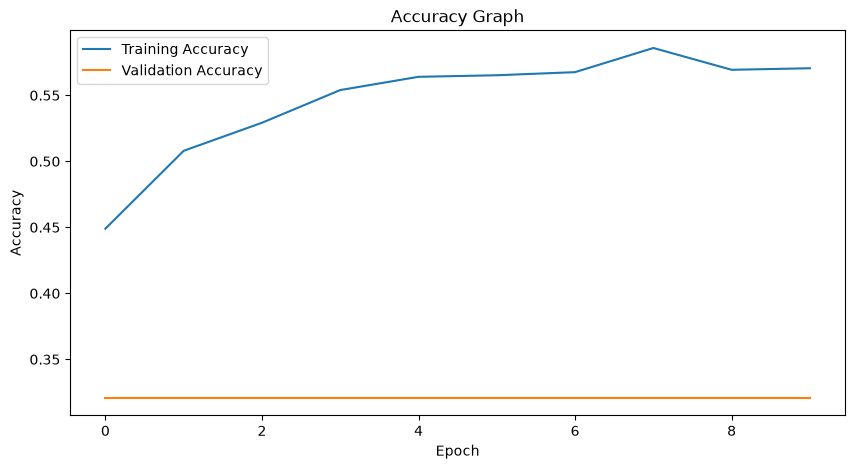

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Accuracy Graph")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

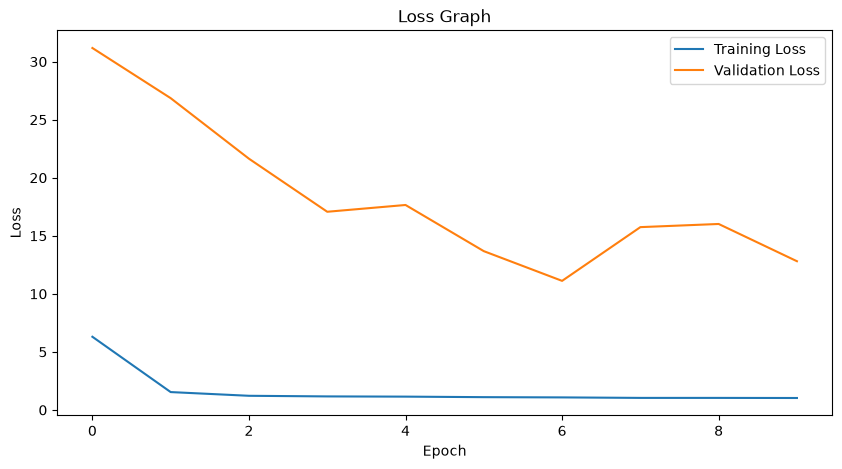

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Loss Graph")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
print("Train Classes:")
print(train_generator.class_indices)

print("\nValidation Classes:")
print(validation_generator.class_indices)

Train Classes:
{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

Validation Classes:
{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


In [ ]:
loss, accuracy = model.evaluate(test_generator)

print("Test Loss :", loss)
print("Test Accuracy :", accuracy)

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 368ms/step - accuracy: 0.3252 - loss: 12.6217
Test Loss : 12.62169361114502
Test Accuracy : 0.3252032399177551


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

import numpy as np

predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)

y_true = test_generator.classes

print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(
            test_generator.class_indices.keys()
        )
    )
)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 168ms/step
              precision    recall  f1-score   support

      glioma       0.33      1.00      0.49        80
  meningioma       0.00      0.00      0.00        63
    no_tumor       0.00      0.00      0.00        49
   pituitary       0.00      0.00      0.00        54

    accuracy                           0.33       246
   macro avg       0.08      0.25      0.12       246
weighted avg       0.11      0.33      0.16       246



c:\Users\Nithin\Brain-Tumor-Classification\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nithin\Brain-Tumor-Classification\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nithin\Brain-Tumor-Classification\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

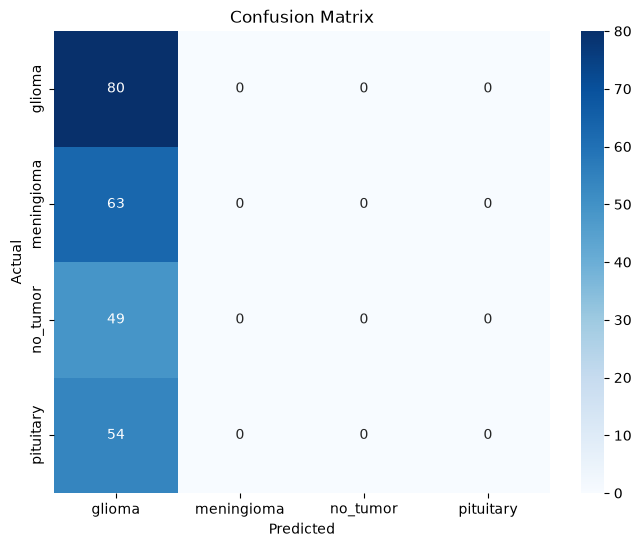

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_generator.class_indices.keys(),
    yticklabels=test_generator.class_indices.keys()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense
)
from tensorflow.keras.models import Model

In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 Loaded")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 Loaded


In [ ]:
x = GlobalAveragePooling2D()(base_model.output)

x = Dense(
    128,
    activation="relu"
)(x)

output = Dense(
    4,
    activation="softmax"
)(x)

model_mobilenet = Model(
    inputs=base_model.input,
    outputs=output
)

model_mobilenet.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model_mobilenet.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 Compiled")

MobileNetV2 Compiled


In [ ]:
history_mobilenet = model_mobilenet.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 795ms/step - accuracy: 0.6903 - loss: 0.7623 - val_accuracy: 0.1972 - val_loss: 4.3344
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 753ms/step - accuracy: 0.7811 - loss: 0.5690 - val_accuracy: 0.1972 - val_loss: 4.4797
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 766ms/step - accuracy: 0.8071 - loss: 0.5012 - val_accuracy: 0.1992 - val_loss: 4.7232
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 770ms/step - accuracy: 0.8348 - loss: 0.4804 - val_accuracy: 0.2151 - val_loss: 4.7417
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 43s 807ms/step - accuracy: 0.8236 - loss: 0.4809 - val_accuracy: 0.1972 - val_loss: 6.0322
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 784ms/step - accuracy: 0.8378 - loss: 0.4440 - val_accuracy: 0.1972 - val_loss: 5.6343
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 780ms/step - accuracy: 0.8360 - loss: 0.4255 - val_accuracy: 0.1972 - val_loss: 6.2561
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 788ms/step - accuracy: 0.8319 - loss: 0.4324 - val_accu

In [ ]:
loss_mobilenet, accuracy_mobilenet = model_mobilenet.evaluate(
    test_generator
)

print("MobileNetV2 Test Loss :", loss_mobilenet)
print("MobileNetV2 Test Accuracy :", accuracy_mobilenet)

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 414ms/step - accuracy: 0.1992 - loss: 6.7820
MobileNetV2 Test Loss : 6.78203821182251
MobileNetV2 Test Accuracy : 0.1991869956254959


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
train_datagen_mobilenet = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

validation_datagen_mobilenet = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen_mobilenet = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

print("MobileNetV2 Generators Ready")


MobileNetV2 Generators Ready


In [5]:
train_dir = "../data/raw/train-20261007T203015Z-1-001/train"
valid_dir = "../data/raw/valid-20261007T203007Z-1-001/valid"
test_dir = "../data/raw/test-20261007T203009Z-1-001/test"

print("Paths Loaded")

Paths Loaded


In [ ]:
train_generator_mobilenet = train_datagen_mobilenet.flow_from_directory(
    train_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

validation_generator_mobilenet = validation_datagen_mobilenet.flow_from_directory(
    valid_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

test_generator_mobilenet = test_datagen_mobilenet.flow_from_directory(
    test_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)


Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense
)
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)

x = Dense(
    128,
    activation="relu"
)(x)

output = Dense(
    4,
    activation="softmax"
)(x)

model_mobilenet_fixed = Model(
    inputs=base_model.input,
    outputs=output
)

model_mobilenet_fixed.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model_mobilenet_fixed.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fixed MobileNetV2 Compiled")


Fixed MobileNetV2 Compiled


In [ ]:
history_mobilenet_fixed = model_mobilenet_fixed.fit(
    train_generator_mobilenet,
    validation_data=validation_generator_mobilenet,
    epochs=10
)


Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 54s 886ms/step - accuracy: 0.7510 - loss: 0.6315 - val_accuracy: 0.8247 - val_loss: 0.5043
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 848ms/step - accuracy: 0.8625 - loss: 0.3642 - val_accuracy: 0.8147 - val_loss: 0.5123
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 44s 833ms/step - accuracy: 0.8885 - loss: 0.2914 - val_accuracy: 0.8207 - val_loss: 0.5098
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 43s 813ms/step - accuracy: 0.9015 - loss: 0.2741 - val_accuracy: 0.8147 - val_loss: 0.5018
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 43s 820ms/step - accuracy: 0.8909 - loss: 0.2877 - val_accuracy: 0.8625 - val_loss: 0.4126
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 843ms/step - accuracy: 0.9251 - loss: 0.2098 - val_accuracy: 0.8227 - val_loss: 0.5199
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 850ms/step - accuracy: 0.9233 - loss: 0.2078 - val_accuracy: 0.8884 - val_loss: 0.3254
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 44s 838ms/step - accuracy: 0.9298 - loss: 0.1953 - val_accu

In [ ]:
loss_mobilenet_fixed, accuracy_mobilenet_fixed = model_mobilenet_fixed.evaluate(
    test_generator_mobilenet
)

print("Test Loss :", loss_mobilenet_fixed)
print("Test Accuracy :", accuracy_mobilenet_fixed)


8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 429ms/step - accuracy: 0.8902 - loss: 0.3716
Test Loss : 0.3716069757938385
Test Accuracy : 0.8902438879013062


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

predictions = model_mobilenet_fixed.predict(
    test_generator_mobilenet
)

y_pred = np.argmax(predictions, axis=1)

y_true = test_generator_mobilenet.classes

print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(
            test_generator_mobilenet.class_indices.keys()
        )
    )
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 671ms/step
              precision    recall  f1-score   support

      glioma       0.94      0.96      0.95        80
  meningioma       0.87      0.75      0.80        63
    no_tumor       0.95      0.84      0.89        49
   pituitary       0.81      1.00      0.89        54

    accuracy                           0.89       246
   macro avg       0.89      0.89      0.88       246
weighted avg       0.90      0.89      0.89       246



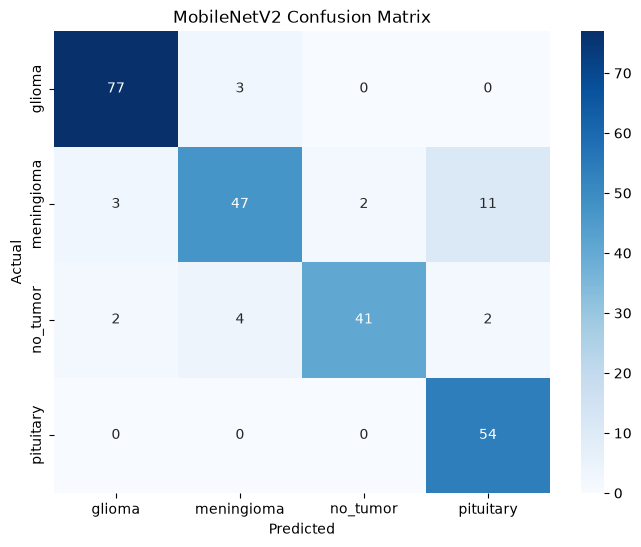

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_generator_mobilenet.class_indices.keys(),
    yticklabels=test_generator_mobilenet.class_indices.keys()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Confusion Matrix")

plt.show()


In [14]:
model_mobilenet_fixed.save(
    "../models/best_model.h5"
)

print("Model Saved")


Model Saved
